<a href="https://colab.research.google.com/github/swarnapatro/AI_KickStart/blob/main/Logistic_Regression_Diabetes_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 Gen AI and Agentic AI Certification Course
## Module: Supervised Learning — Logistic Regression
### Use Case: **Pima Indians Diabetes Dataset**

Dataset source: [Kaggle — Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)

---

**Instructions for students:**
- Run each cell in order (Shift + Enter).
- Read the explanation in each text cell before running the code below it.
- Two data-loading options are provided (Kaggle API and a direct public CSV mirror) — use whichever
  works in your environment.
- Try the **Practice Exercises** at the end on your own.

This notebook is the **companion to the Multiple Linear Regression notebook** and uses the **same
dataset**, so you can compare the two techniques directly.


## 1️⃣ Recap: From Linear Regression to Logistic Regression

In the previous session we used **Multiple Linear Regression (MLR)** to predict a **continuous**
number:

$$ Y = b_0 + b_1X_1 + b_2X_2 + \dots + b_nX_n $$

But look carefully at the `Outcome` column of our dataset. It is **not** a continuous number — it
only ever takes **two values**:

| Outcome | Meaning |
|---|---|
| `0` | Patient does **not** have diabetes |
| `1` | Patient **has** diabetes |

If we push a binary column like this through Linear Regression, the model happily predicts values
like `-0.13` or `1.42` — which are **impossible**, because a patient cannot be "-13% diabetic" or
"142% diabetic". A straight line simply cannot respect the 0–1 boundary, and it has no notion of
*probability*.

> 🎯 **This is exactly the gap Logistic Regression fills.** When the target is a **category**
> (yes/no, diabetic/not diabetic, spam/not spam), we need a **classification** model — not a
> regression model.

### So what changes?

| | Linear Regression | Logistic Regression |
|---|---|---|
| **Predicts** | a number (BMI, price, weight) | a **class** (0 or 1) |
| **Output range** | −∞ to +∞ | **0 to 1** (a probability) |
| **Model type** | Regression | **Classification** |
| **Evaluated with** | RMSE, R² | **Accuracy, Precision, Recall, F1, ROC-AUC** |

⚠️ **Note on the name:** Logistic Regression has the word *"regression"* in it, but it is a
**classification algorithm**. The name refers to the weighted sum happening inside it. This confuses
almost everyone at first — say it out loud once and move on!


## 2️⃣ How Logistic Regression Works — The Sigmoid

Logistic Regression works in **two steps**:

**Step 1 — the same weighted sum you already know** (exactly like Linear Regression):

$$ z = b_0 + b_1X_1 + b_2X_2 + \dots + b_nX_n $$

This `z` can be any number, from very negative to very positive.

**Step 2 — squash it into a probability using the sigmoid function:**

$$ p = \sigma(z) = \frac{1}{1 + e^{-z}} $$

The **sigmoid** is an S-shaped curve that maps *any* number into the range **0 to 1**:
- a large **negative** `z` → probability near **0**
- `z = 0` → probability exactly **0.5**
- a large **positive** `z` → probability near **1**

**Step 3 — apply a threshold to make the final decision:**

$$ \text{if } p \geq 0.5 \Rightarrow \text{predict } 1 \ (\text{diabetic}), \quad
\text{else} \Rightarrow \text{predict } 0 \ (\text{not diabetic}) $$

The threshold `0.5` is just a **default** — later in this notebook we will **change it deliberately**
to catch more diabetic patients, which is a critically important idea in medical screening.

Run the cell below to *see* the sigmoid curve.


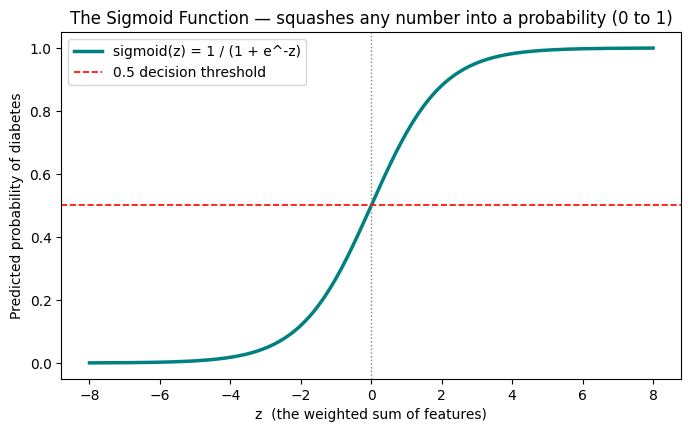

Notice: z = -6 gives p = 0.0025   -> predicts 0 (not diabetic)
        z =  0 gives p = 0.5      -> exactly on the threshold
        z =  6 gives p = 0.9975   -> predicts 1 (diabetic)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 4.5))
plt.plot(z, sigmoid, color='teal', linewidth=2.5, label='sigmoid(z) = 1 / (1 + e^-z)')
plt.axhline(y=0.5, color='red', linestyle='--', linewidth=1.2, label='0.5 decision threshold')
plt.axvline(x=0, color='gray', linestyle=':', linewidth=1)
plt.title('The Sigmoid Function — squashes any number into a probability (0 to 1)')
plt.xlabel('z  (the weighted sum of features)')
plt.ylabel('Predicted probability of diabetes')
plt.ylim(-0.05, 1.05)
plt.legend()
plt.show()

print("Notice: z = -6 gives p =", round(1 / (1 + np.exp(6)), 4), "  -> predicts 0 (not diabetic)")
print("        z =  0 gives p =", round(1 / (1 + np.exp(0)), 4), "     -> exactly on the threshold")
print("        z =  6 gives p =", round(1 / (1 + np.exp(-6)), 4), "  -> predicts 1 (diabetic)")


## 3️⃣ Step 1: Import Required Libraries

Notice the imports have changed from the MLR notebook:
- `LogisticRegression` replaces `LinearRegression`
- the metrics are **classification** metrics (`confusion_matrix`, `classification_report`,
  `roc_auc_score`) instead of `mean_squared_error` / `r2_score`


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             roc_auc_score, roc_curve)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

print("✅ Libraries imported successfully!")


✅ Libraries imported successfully!


## 4️⃣ Step 2: Load the Dataset

https://www.kaggle.com/datasets/jamaltariqcheema/pima-indians-diabetes-dataset

You have **two options** to load the dataset in Google Colab. Use whichever is convenient.

### Option A — Load directly from Kaggle (recommended for authenticity)
1. Go to your Kaggle account → **Settings** → **API** → **Create New Token**. This downloads a
   `kaggle.json` file.
2. Run the cell below, and when prompted, **upload that `kaggle.json` file**.

### Option B — Load from a public CSV mirror (quick, no login needed)
This is the **same Pima Indians Diabetes dataset**, hosted as a plain CSV for quick classroom use.
This is the option used by default in this notebook so everyone can run it instantly without any
Kaggle account setup.


In [ ]:
# ------------------------------------------------------------------
# OPTION A: Load directly from Kaggle (uncomment to use)
# ------------------------------------------------------------------
# from google.colab import files
# files.upload()   # upload your kaggle.json when prompted
#
# !mkdir -p ~/.kaggle
# !cp kaggle.json ~/.kaggle/
# !chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d uciml/pima-indians-diabetes-database
# !unzip -o pima-indians-diabetes-database.zip
# df = pd.read_csv('diabetes.csv')

# ------------------------------------------------------------------
# OPTION B: Load from a public CSV mirror (used by default here)
# ------------------------------------------------------------------
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

column_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

df = pd.read_csv(url, names=column_names)

print("✅ Dataset loaded successfully!")
df.head(10)


✅ Dataset loaded successfully!


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


## 5️⃣ Step 3: Explore the Dataset

Before modeling, always inspect:
- **Shape** (rows & columns)
- **Data types**
- **Missing values**
- **Statistical summary** (mean, min, max, std deviation, etc.)


In [ ]:
print("Shape of dataset:", df.shape)
print("\nData types:\n")
print(df.dtypes)
print("\nMissing values per column:\n")
print(df.isnull().sum())


Shape of dataset: (768, 9)

Data types:

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values per column:

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 6️⃣ Step 4: Data Cleaning — Handling Hidden Missing Values

Exactly as in the MLR notebook, look at `df.describe()` above: columns like **Glucose,
BloodPressure, SkinThickness, Insulin, and BMI** have a **minimum value of 0** — but biologically, a
living person cannot have 0 Glucose, 0 Blood Pressure, or 0 BMI!

These zeros are actually **missing values** recorded as `0` instead of `NaN`. If we don't fix this,
our classifier will learn **incorrect patterns** from impossible values.

**Fix:** Replace these `0`s with `NaN`, then fill (**impute**) them with the **median** of that
column (median is preferred over mean because it is less sensitive to outliers).

> ⚠️ **Important:** we do **not** touch `Outcome` — its `0` means "no diabetes", which is a perfectly
> valid value. Only the *measurement* columns have impossible zeros.


In [ ]:
# Columns where 0 is biologically impossible and likely represents missing data
cols_with_invalid_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Replacing 0 with NaN
df[cols_with_invalid_zero] = df[cols_with_invalid_zero].replace(0, np.nan)

print("Missing values after replacing invalid zeros:\n")
print(df.isnull().sum())


Missing values after replacing invalid zeros:

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
# Imputing missing values with the median of each column
for col in cols_with_invalid_zero:
    df[col] = df[col].fillna(df[col].median())

print("✅ Missing values handled successfully!")
print("\nMissing values now:\n")
print(df.isnull().sum())


✅ Missing values handled successfully!

Missing values now:

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## 7️⃣ Step 5: Exploratory Data Analysis (EDA)

For a **classification** problem, the EDA questions are different from regression. We now ask:

1. **Is the target balanced?** How many diabetic vs non-diabetic patients do we have? This decides
   whether *accuracy* will be a trustworthy metric.
2. **Which features separate the two classes?** If diabetic patients have visibly higher Glucose,
   then Glucose will be a useful predictor.
3. **Correlation heatmap** — to see which features relate to `Outcome`.


Class distribution:
  Outcome = 0 (No Diabetes) : 500  (65.1%)
  Outcome = 1 (Diabetes)    : 268  (34.9%)


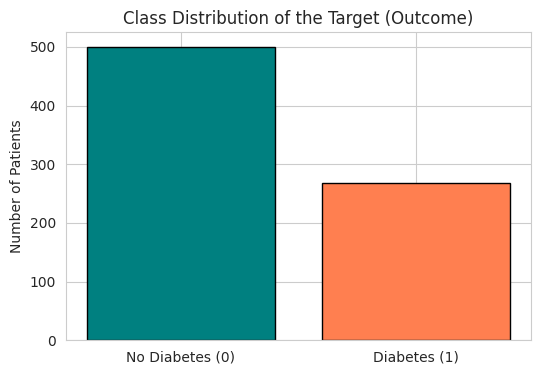

In [ ]:
outcome_counts = df['Outcome'].value_counts().sort_index()

print("Class distribution:")
print(f"  Outcome = 0 (No Diabetes) : {outcome_counts[0]}  ({outcome_counts[0]/len(df)*100:.1f}%)")
print(f"  Outcome = 1 (Diabetes)    : {outcome_counts[1]}  ({outcome_counts[1]/len(df)*100:.1f}%)")

plt.figure(figsize=(6, 4))
plt.bar(['No Diabetes (0)', 'Diabetes (1)'], outcome_counts.values,
        color=['teal', 'coral'], edgecolor='black')
plt.title('Class Distribution of the Target (Outcome)')
plt.ylabel('Number of Patients')
plt.show()


> 💡 **Read this carefully — it shapes the whole notebook.** Roughly **65%** of patients are
> non-diabetic and **35%** are diabetic. This is **imbalanced**.
>
> Why does that matter? A lazy model that *always* predicts "no diabetes" would be **65% accurate**
> while catching **zero** diabetic patients. Accuracy alone would call that a decent model — it is
> useless. This is why we will rely on **precision, recall and F1**, not just accuracy.


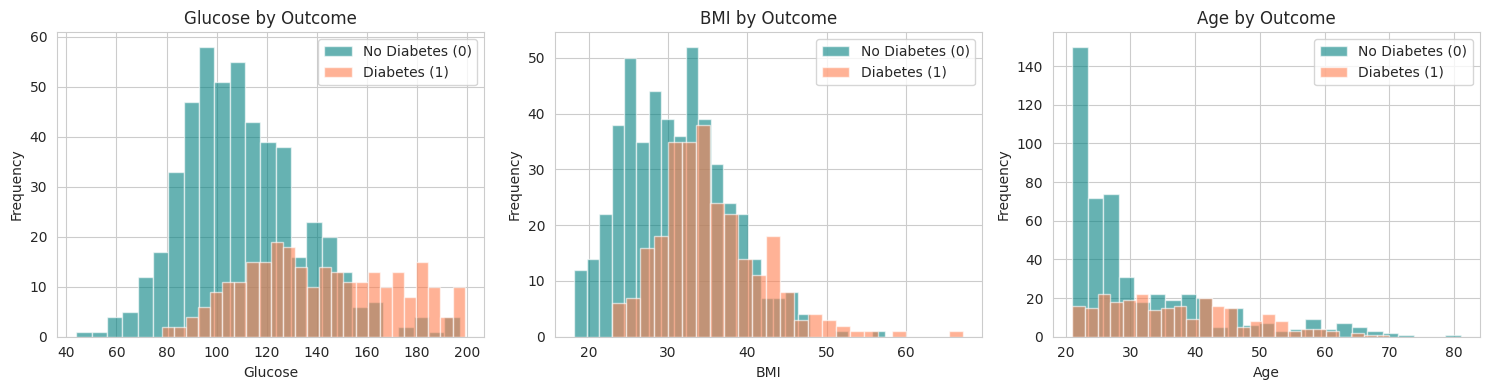

In [ ]:
# Do diabetic and non-diabetic patients differ on key measurements?
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, ['Glucose', 'BMI', 'Age']):
    df[df['Outcome'] == 0][feature].plot(kind='hist', bins=25, alpha=0.6,
                                         ax=ax, color='teal', label='No Diabetes (0)')
    df[df['Outcome'] == 1][feature].plot(kind='hist', bins=25, alpha=0.6,
                                         ax=ax, color='coral', label='Diabetes (1)')
    ax.set_title(f'{feature} by Outcome')
    ax.set_xlabel(feature)
    ax.legend()

plt.tight_layout()
plt.show()


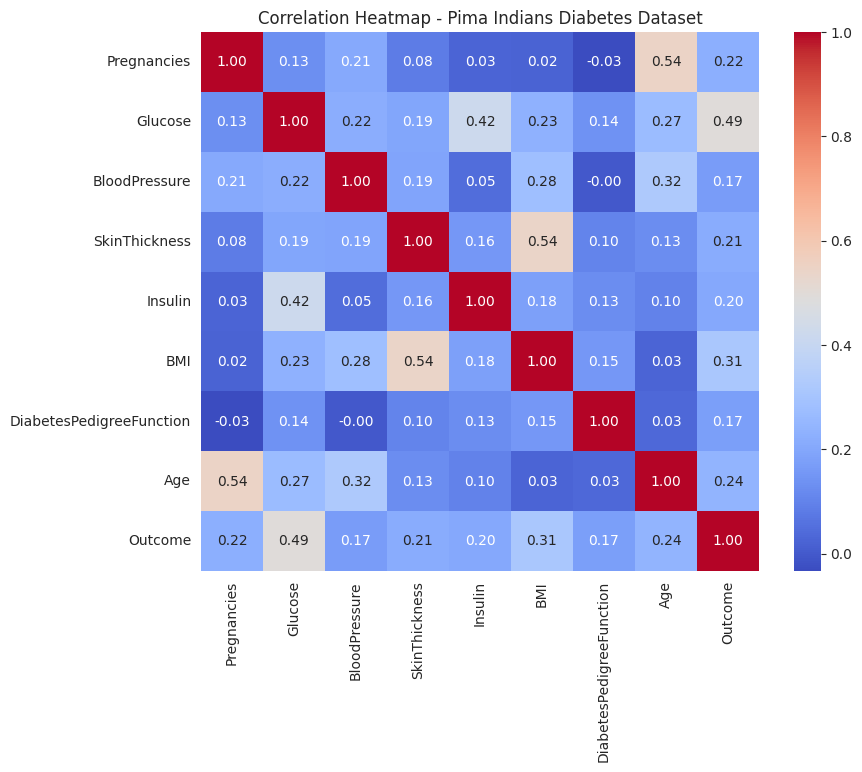

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Correlation Heatmap - Pima Indians Diabetes Dataset')
plt.show()
# 1.000000 	0.137979 	0.202285 	0.086119 	0.064170 	0.013430 	-0.051994 	0.535957 correlation number from scaler data

**How to read these charts:** In the histograms, notice how the **Glucose** distribution for diabetic
patients (coral) is clearly shifted to the right of the non-diabetic patients (teal) — the two
classes *separate* well on Glucose. That tells us Glucose will be a strong predictor.

In the heatmap, look at the **`Outcome` row/column**: `Glucose` has the highest correlation with
Outcome, followed by `BMI` and `Age`. These are the features doing most of the predictive work.


## 8️⃣ Step 6: Define Features (X) and Target (y)

Here is the **key difference from the MLR notebook**:

- In the **MLR** notebook, `Outcome` was used as one of the **features** (an input), and we predicted
  a continuous column.
- In **this** notebook, `Outcome` is the **target** (`y`) — the class we are trying to predict — and
  every other column becomes a **feature** (`X`).

- **Target (y):** `Outcome` — the binary class (0 = no diabetes, 1 = diabetes)
- **Features (X):** `Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI,
  DiabetesPedigreeFunction, Age`


In [ ]:
X = df.drop(columns=['Outcome'])   # All columns except Outcome = features
y = df['Outcome']                  # Target variable (the class: 0 or 1)

print("Feature columns:", list(X.columns))
print("Target column  : Outcome")
print("\nX shape:", X.shape)
print("y shape:", y.shape)
print("\nFirst 5 rows of X:")
display(X.head())
print("First 5 values of y:", list(y.head()))


Feature columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Target column  : Outcome

X shape: (768, 8)
y shape: (768,)

First 5 rows of X:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


First 5 values of y: [1, 0, 1, 0, 1]


## 9️⃣ Step 7: Train-Test Split (with Stratification)

As before, we split into **80% training** and **20% testing** so we can evaluate on data the model
has never seen.

**One new argument: `stratify=y`.** Because our classes are imbalanced (65% / 35%), a purely random
split could accidentally put too few diabetic patients in the test set, making our evaluation
unreliable. `stratify=y` forces **both** the training and test sets to keep the *same class
proportions* as the full dataset.

> 🎯 **Rule of thumb:** for classification, always use `stratify=y`.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

print("\nClass balance is preserved in both sets:")
print("  Train -> diabetic:", f"{y_train.mean()*100:.1f}%")
print("  Test  -> diabetic:", f"{y_test.mean()*100:.1f}%")


Training samples: 614
Testing samples : 154

Class balance is preserved in both sets:
  Train -> diabetic: 34.9%
  Test  -> diabetic: 35.1%


## 🔟 Step 8: Feature Scaling (Standardization)

Our features are on very different scales — `Pregnancies` ranges roughly 0–17, while `Insulin` runs
into the hundreds.

For **Linear Regression**, scaling was *optional* (nice for comparing coefficients). For **Logistic
Regression**, scaling is **more important**, because the model is fitted with an iterative optimizer
(gradient-based). Unscaled features can make it **converge slowly** or throw a
`ConvergenceWarning`.

We use **StandardScaler**, which transforms each feature to **mean = 0** and **standard deviation = 1**.


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # fit on training data only
X_test_scaled = scaler.transform(X_test)         # apply same transformation to test data

# Converting back to DataFrame for readability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

X_train_scaled.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,-0.851355,-1.056427,-0.826740,-1.918187,-1.203361,-0.769477,0.310794,-0.792169
711,0.356576,0.144399,0.477772,-0.229874,-1.470195,-0.417498,-0.116439,0.561034
373,-0.549372,-0.556083,-1.152868,1.233330,-0.555335,0.359790,-0.764862,-0.707594
46,-0.851355,0.811525,-1.315932,-0.004766,-0.161437,-0.402832,0.262314,-0.369293
682,-1.153338,-0.889646,-0.663676,1.120776,-0.415565,1.782373,-0.337630,-0.961320


In [ ]:
X_train_scaled.corr()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Pregnancies,1.000000,0.137979,0.202285,0.086119,0.064170,0.013430,-0.051994,0.535957
Glucose,0.137979,1.000000,0.219076,0.224007,0.450821,0.225825,0.139209,0.289605
BloodPressure,0.202285,0.219076,1.000000,0.180492,0.084672,0.269571,-0.004889,0.315147
SkinThickness,0.086119,0.224007,0.180492,1.000000,0.222468,0.538605,0.109607,0.135448
Insulin,0.064170,0.450821,0.084672,0.222468,1.000000,0.205477,0.191179,0.122132
BMI,0.013430,0.225825,0.269571,0.538605,0.205477,1.000000,0.163540,0.028405
DiabetesPedigreeFunction,-0.051994,0.139209,-0.004889,0.109607,0.191179,0.163540,1.000000,0.025108
Age,0.535957,0.289605,0.315147,0.135448,0.122132,0.028405,0.025108,1.000000


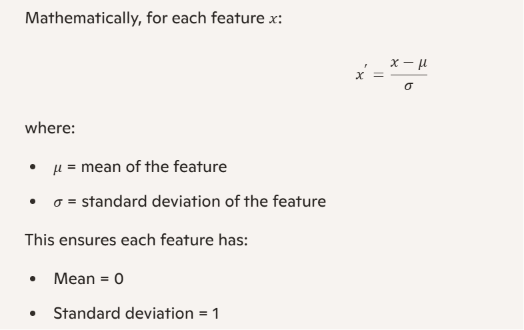

> 💡 **Important:** We call `fit_transform()` only on the **training** data, and `transform()`
> (without fit) on the **test** data. This prevents **data leakage** — the test set must remain
> completely unseen during training, including during scaling.


## 1️⃣1️⃣ Step 9: Train the Logistic Regression Model

The code is almost identical to MLR — only the model class changed. This is the beauty of
scikit-learn: **every model follows the same `.fit()` / `.predict()` pattern.**

- `max_iter=1000` gives the optimizer enough iterations to converge.
- `random_state=42` makes the result reproducible.


In [ ]:
diabetes_model = LogisticRegression(max_iter=1000, random_state=42)

diabetes_model.fit(X_train_scaled, y_train)

print("✅ Model training complete!")
print("\nClasses the model learned:", diabetes_model.classes_)


✅ Model training complete!

Classes the model learned: [0 1]


## 1️⃣2️⃣ Step 10: Interpreting the Model's Coefficients

In Logistic Regression the coefficients act on the **log-odds** of being diabetic, not directly on
the probability. Two ways to read them:

**1. The sign and size of the coefficient** (features are scaled, so these are comparable):
- **Positive coefficient** → increases the probability of diabetes
- **Negative coefficient** → decreases it
- **Larger absolute value** → stronger influence

**2. The Odds Ratio = `exp(coefficient)`** — much friendlier to explain to a doctor:
- Odds Ratio **> 1** → the odds of diabetes **increase** as the feature increases
- Odds Ratio **< 1** → the odds **decrease**
- Odds Ratio **= 1** → no effect

*Example:* an Odds Ratio of `2.1` for Glucose means that for a one-standard-deviation rise in
Glucose, the **odds** of having diabetes become about **2.1× higher**, holding other features
constant.


In [ ]:
coefficients_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': diabetes_model.coef_[0],
    'Odds_Ratio': np.exp(diabetes_model.coef_[0])
}).sort_values(by='Coefficient', key=abs, ascending=False)

print(f"Intercept (b0): {diabetes_model.intercept_[0]:.3f}\n")
coefficients_df


Intercept (b0): -0.872



,Feature,Coefficient,Odds_Ratio
1,Glucose,1.182511,3.262558
5,BMI,0.688735,1.991194
0,Pregnancies,0.377502,1.458637
6,DiabetesPedigreeFunction,0.233386,1.262869
7,Age,0.147798,1.159279
4,Insulin,-0.066157,0.935983
2,BloodPressure,-0.044066,0.956891
3,SkinThickness,0.028225,1.028627


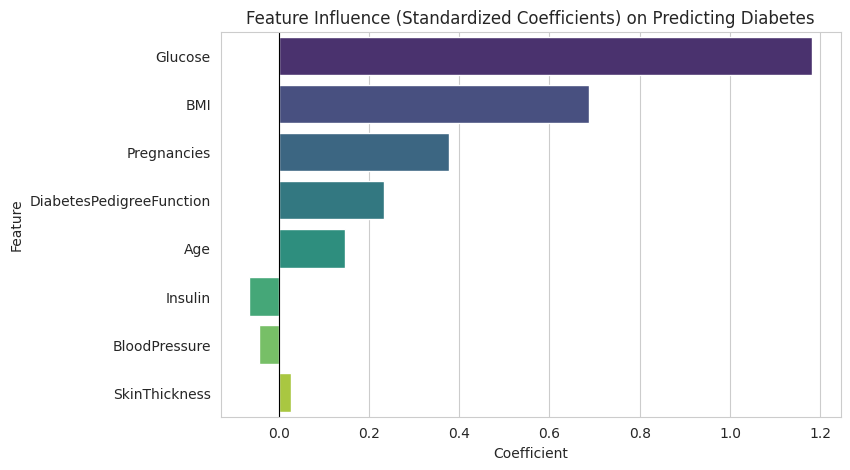

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=coefficients_df, x='Coefficient', y='Feature',
            hue='Feature', palette='viridis', legend=False)
plt.title('Feature Influence (Standardized Coefficients) on Predicting Diabetes')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.show()


**What you should see:** `Glucose` has by far the largest positive coefficient — unsurprising, since
diabetes is defined by blood-sugar regulation. `BMI`, `Pregnancies` and `DiabetesPedigreeFunction`
(family history) also push the prediction toward diabetes.


## 1️⃣3️⃣ Step 11: Making Predictions on Test Data

A classifier gives you **two** kinds of output — and understanding the difference is essential:

| Method | Returns | Example |
|---|---|---|
| `.predict(X)` | the final **class** (0 or 1) | `1` |
| `.predict_proba(X)` | the **probability** of each class | `[0.23, 0.77]` |

`.predict()` is simply `.predict_proba()` compared against the **0.5 threshold**. Look at the table
below: any row with `Probability_Diabetes >= 0.5` gets predicted as `1`.


In [ ]:
y_pred = diabetes_model.predict(X_test_scaled)                    # the class: 0 or 1
y_pred_proba = diabetes_model.predict_proba(X_test_scaled)[:, 1]  # probability of class 1

comparison_df = pd.DataFrame({
    'Actual_Outcome': y_test.values,
    'Predicted_Outcome': y_pred,
    'Probability_Diabetes': np.round(y_pred_proba, 3)
}).reset_index(drop=True)

comparison_df.head(15)


,Actual_Outcome,Predicted_Outcome,Probability_Diabetes
0,0,1,0.610
1,0,0,0.118
2,0,0,0.293
3,1,0,0.251
4,0,0,0.033
5,0,0,0.169
6,1,0,0.488
7,1,1,0.924
8,0,0,0.081
9,0,1,0.839


👉 **Look for a row where the probability is close to 0.5** (say 0.48 or 0.52). Those are the
patients the model is *least sure* about — and they are exactly the ones a threshold change (Step 15)
will flip.


## 1️⃣4️⃣ Step 12: The Confusion Matrix

Every prediction lands in **one of four boxes**. This little 2×2 table is the foundation of *every*
classification metric.

|  | Predicted 0 (No Diabetes) | Predicted 1 (Diabetes) |
|---|---|---|
| **Actual 0 (No Diabetes)** | ✅ True Negative (TN) | ⚠️ **False Positive (FP)** — false alarm |
| **Actual 1 (Diabetes)** | ❌ **False Negative (FN)** — *missed patient* | ✅ True Positive (TP) |

The two error cells are **not equally bad**:
- **False Positive (FP):** we tell a healthy person they may be diabetic → extra tests, some anxiety.
- **False Negative (FN):** we tell a **diabetic person they are healthy** → *they go untreated*.

> 🎯 In medical screening, a **False Negative is far more dangerous** than a False Positive. Keep
> your eye on that FN cell.


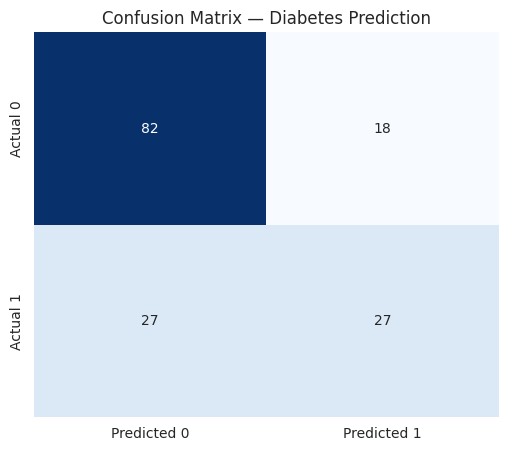

True Negatives  (TN) = 82   -> healthy, correctly cleared
False Positives (FP) = 18   -> healthy, wrongly flagged (false alarm)
False Negatives (FN) = 27   -> DIABETIC, but MISSED  <-- the dangerous error
True Positives  (TP) = 27   -> diabetic, correctly caught


In [ ]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix — Diabetes Prediction')
plt.show()

print(f"True Negatives  (TN) = {tn}   -> healthy, correctly cleared")
print(f"False Positives (FP) = {fp}   -> healthy, wrongly flagged (false alarm)")
print(f"False Negatives (FN) = {fn}   -> DIABETIC, but MISSED  <-- the dangerous error")
print(f"True Positives  (TP) = {tp}   -> diabetic, correctly caught")


## 1️⃣5️⃣ Step 13: Classification Metrics — Beyond Accuracy

These are the classification counterparts of MAE / RMSE / R² from the MLR notebook.

| Metric | Formula | Plain English | Care about it when… |
|---|---|---|---|
| **Accuracy** | `(TP+TN) / all` | overall % correct | classes are balanced |
| **Precision** | `TP / (TP+FP)` | of those we **flagged**, how many were right? | false alarms are costly |
| **Recall** *(Sensitivity)* | `TP / (TP+FN)` | of the **real diabetics**, how many did we catch? | **misses are costly** |
| **F1 Score** | harmonic mean of P & R | one number balancing both | you need both |
| **ROC-AUC** | area under ROC curve | how well the model **ranks** patients | comparing models |

**Why accuracy alone lies here:** our data is 65% non-diabetic. A model that always predicts "no
diabetes" scores 65% accuracy while catching **zero** diabetics. Always check **recall** on the class
you care about.




In [ ]:
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
roc_auc   = roc_auc_score(y_test, y_pred_proba)   # note: uses PROBABILITIES, not pred classes,

print("📊 MODEL EVALUATION METRICS")
print("-" * 45)
print(f"Accuracy                       : {accuracy:.3f}")
print(f"Precision (of flagged, correct): {precision:.3f}")
print(f"Recall    (of diabetics, found): {recall:.3f}")
print(f"F1 Score                       : {f1:.3f}")
print(f"ROC-AUC                        : {roc_auc:.3f}")

print("\n\nFull classification report (per class):\n")
print(classification_report(y_test, y_pred,
                            target_names=['No Diabetes (0)', 'Diabetes (1)']))


📊 MODEL EVALUATION METRICS
---------------------------------------------
Accuracy                       : 0.708
Precision (of flagged, correct): 0.600
Recall    (of diabetics, found): 0.500
F1 Score                       : 0.545
ROC-AUC                        : 0.813


Full classification report (per class):

                 precision    recall  f1-score   support

No Diabetes (0)       0.75      0.82      0.78       100
   Diabetes (1)       0.60      0.50      0.55        54

       accuracy                           0.71       154
      macro avg       0.68      0.66      0.67       154
   weighted avg       0.70      0.71      0.70       154



> 💡 **Read the output above and notice the story it tells.** Accuracy looks respectable, but the
> **recall for class 1 (Diabetes) is noticeably lower** — the model is missing a meaningful share of
> the diabetic patients. A number that looks fine overall is hiding the error that matters most.
>
> The baseline for comparison: always predicting 0 would give ~65% accuracy and **0% recall**.


Receiver Operating Characteristic - Area Under the Curve
## 1️⃣6️⃣ Step 14: The ROC Curve and AUC

The `0.5` threshold is just one choice. The **ROC curve** shows what happens across **every possible
threshold** — plotting the True Positive Rate (recall) against the False Positive Rate.

- A model that ranks perfectly hugs the **top-left corner** → **AUC = 1.0**
- Random guessing follows the **diagonal** → **AUC = 0.5**

**AUC answers:** *"If I pick one diabetic and one non-diabetic patient at random, how often does the
model give the diabetic patient a higher probability?"* An AUC of 0.83 means about 83% of the time.


How to interpret AUC:

    An AUC of 1.0 indicates a perfect model that correctly classifies every instance.
    An AUC of 0.5 suggests the model performs no better than random guessing.
    An AUC between 0.5 and 1.0 indicates varying degrees of model performance, with higher values being better.


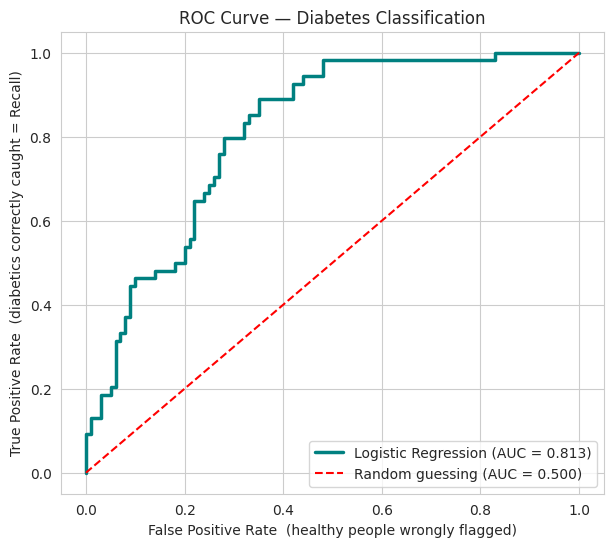

ROC-AUC = 0.813


In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='teal', linewidth=2.5, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'r--', linewidth=1.5, label='Random guessing (AUC = 0.500)')
plt.title('ROC Curve — Diabetes Classification')
plt.xlabel('False Positive Rate  (healthy people wrongly flagged)')
plt.ylabel('True Positive Rate  (diabetics correctly caught = Recall)')
plt.legend(loc='lower right')
plt.show()

print(f"ROC-AUC = {roc_auc:.3f}")


## 1️⃣7️⃣ Step 15: Tuning the Decision Threshold ⭐

**This is the most important practical idea in this notebook.**

The `0.5` cutoff is a **default, not a law**. Because a missed diabetic patient (FN) is more harmful
than a false alarm (FP), we can **lower the threshold** so the model flags a patient as diabetic on
weaker evidence.

- **Lower threshold** (e.g. 0.3) → catches more diabetics (**recall ↑**) but raises false alarms
  (**precision ↓**)
- **Higher threshold** (e.g. 0.7) → fewer false alarms (**precision ↑**) but misses more patients
  (**recall ↓**)

You cannot maximise both. **Choosing the threshold is choosing which error you are willing to make.**
Run the cell and watch recall climb as the threshold drops.


In [ ]:
print(f"{'Threshold':>10} | {'Precision':>9} | {'Recall':>7} | {'F1':>6} | {'Missed (FN)':>11}")
print("-" * 60)

for t in [0.7, 0.6, 0.5, 0.4, 0.3, 0.2]:
    y_pred_t = (y_pred_proba >= t).astype(int)   # apply OUR threshold instead of 0.5
    p = precision_score(y_test, y_pred_t, zero_division=0)
    r = recall_score(y_test, y_pred_t, zero_division=0)
    f = f1_score(y_test, y_pred_t, zero_division=0)
    fn_count = confusion_matrix(y_test, y_pred_t)[1, 0]
    star = "   <-- default" if t == 0.5 else ""
    print(f"{t:>10.1f} | {p:>9.3f} | {r:>7.3f} | {f:>6.3f} | {fn_count:>11}{star}")

print("\n👉 As the threshold falls, RECALL rises and MISSED PATIENTS (FN) fall —")
print("   but PRECISION drops because we raise more false alarms. That is the trade-off.")


 Threshold | Precision |  Recall |     F1 | Missed (FN)
------------------------------------------------------------
       0.7 |     0.714 |   0.370 |  0.488 |          34
       0.6 |     0.641 |   0.463 |  0.538 |          29
       0.5 |     0.600 |   0.500 |  0.545 |          27   <-- default
       0.4 |     0.614 |   0.648 |  0.631 |          19
       0.3 |     0.597 |   0.796 |  0.683 |          11
       0.2 |     0.552 |   0.889 |  0.681 |           6

👉 As the threshold falls, RECALL rises and MISSED PATIENTS (FN) fall —
   but PRECISION drops because we raise more false alarms. That is the trade-off.


> 🎯 **The GenAI connection:** this exact trade-off governs **safety guardrails** in LLM
> applications. A content filter is a classifier too — tune it for **high recall** and it blocks more
> harmful content but also over-blocks harmless requests (low precision). Tune it for high precision
> and unsafe content slips through. Same confusion matrix, same dial, much higher stakes.


## 1️⃣8️⃣ Step 16: Cross-Validation — Is Our Score Trustworthy?

Our metrics came from **one** train/test split. What if we got a lucky (or unlucky) split?

**Stratified K-Fold Cross-Validation** cuts the data into 5 folds, trains on 4 and tests on the 1
left out, and rotates so **every fold is tested exactly once**. Averaging the 5 scores gives a far
more trustworthy estimate — and the **standard deviation** tells us how stable the model is.

We use **Stratified** K-Fold (not plain K-Fold) so each fold keeps the same 65/35 class balance.

> ⚠️ **A subtle but critical detail — avoid data leakage!** If we scaled the whole `X` *before*
> cross-validation, the scaler would peek at every fold's test data (it would learn their mean and
> standard deviation). That is **leakage**, and it inflates the scores.
>
> The correct approach is a **`Pipeline`**: it re-fits the scaler *inside* each fold, using only that
> fold's training portion. `make_pipeline(StandardScaler(), LogisticRegression())` bundles the two
> steps into a single model object that `cross_val_score` can use safely.

What is an "Iteration"? Not an epoch: In algorithms like Scikit-Learn's LogisticRegression, one iteration is one step taken by the mathematical solver to get closer to the best answer.


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# A Pipeline re-fits the scaler INSIDE each fold -> no data leakage.
pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Note: we pass the FULL, UNSCALED X and y — cross_val_score does the splitting internally.
for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    scores = cross_val_score(pipeline, X, y, cv=skf, scoring=metric)
    print(f"{metric:>10} : {scores.mean():.3f}  (+/- {scores.std():.3f})   folds = {np.round(scores, 3)}")

print("\n👉 A LOW standard deviation means the model performs consistently across different")
print("   slices of data. A HIGH one would warn us the score is fragile.")


  accuracy : 0.773  (+/- 0.016)   folds = [0.773 0.799 0.779 0.752 0.765]
 precision : 0.729  (+/- 0.059)   folds = [0.721 0.829 0.75  0.683 0.66 ]
    recall : 0.571  (+/- 0.047)   folds = [0.574 0.537 0.556 0.528 0.66 ]
        f1 : 0.637  (+/- 0.022)   folds = [0.639 0.652 0.638 0.596 0.66 ]
   roc_auc : 0.837  (+/- 0.020)   folds = [0.825 0.867 0.852 0.829 0.81 ]

👉 A LOW standard deviation means the model performs consistently across different
   slices of data. A HIGH one would warn us the score is fragile.



    Accuracy (0.773 ± 0.016): The model is, on average, 77.3% correct in its predictions. The low standard deviation (0.016) shows this is a very consistent result across the different folds.
    Precision (0.729 ± 0.059): When the model predicts diabetes, it is correct about 72.9% of the time. The standard deviation is a bit higher here, meaning precision varied a bit more between folds, but it's still reasonable.
    Recall (0.571 ± 0.047): The model correctly identifies 57.1% of all actual diabetic patients. This is often the most critical metric in medical screening, and the consistency is good.
    F1 Score (0.637 ± 0.022): This is the harmonic mean of precision and recall, balancing both. The average F1 score is 63.7%, again with low variability.
    ROC-AUC (0.837 ± 0.020): The model has an average AUC of 0.837, which is a good overall measure of its ability to distinguish between diabetic and non-diabetic patients, with very consistent performance across folds.

In summary, the cross-validation results indicate a fairly robust and consistent model performance, particularly given the low standard deviations across all metrics. This means you can trust these performance estimates more than if they came from a single train-test split

## 1️⃣9️⃣ Step 17: Predicting Diabetes for a New Patient Record

Let's use the trained model on a **brand-new hypothetical patient**. Notice we get **both** a
probability and a class — and we can apply our own threshold.

👉 **Try changing the values below** (especially `Glucose` and `BMI`) to see how the predicted
probability changes!


In [ ]:
# 🔧 Feel free to change these values to any realistic patient record
new_patient = pd.DataFrame({
    'Pregnancies': [0],
    'Glucose': [100],
    'BloodPressure': [70],
    'SkinThickness': [28],
    'Insulin': [100],
    'BMI': [50.5],
    'DiabetesPedigreeFunction': [0.5],
    'Age': [45],
})

# Important: apply the SAME scaler fitted on the training data
new_patient_scaled = pd.DataFrame(
    scaler.transform(new_patient), columns=X.columns
)

probability = diabetes_model.predict_proba(new_patient_scaled)[0][1]
prediction = diabetes_model.predict(new_patient_scaled)[0]

print(f"Probability of diabetes : {probability:.3f}")
print(f"Prediction as per the predictability : {'DIABETIC (1)' if prediction == 1 else 'NOT DIABETIC (0)'}")
print(f"Prediction as per the probability : {'DIABETIC (1)' if probability >= 0.5 else 'NOT DIABETIC (0)'}")
print("\n(Notice how the SAME patient can get a different label at a different threshold.)")


## ✅ Summary — What We Learned

1. **Logistic Regression** is a **classification** algorithm (despite its name). It predicts a
   **class**, not a number, by passing a weighted sum through the **sigmoid** to get a probability,
   then applying a **threshold**.
2. We used the **same dataset** as the MLR notebook, but `Outcome` moved from being a *feature* to
   being the **target** — because a binary column should be *classified*, not *regressed*.
3. Because the data is **imbalanced (65/35)**, we used `stratify=y` in the split and Stratified
   K-Fold in cross-validation.
4. **Accuracy alone is misleading.** We evaluated with the **confusion matrix**, **precision**,
   **recall**, **F1** and **ROC-AUC** — and paid special attention to **False Negatives** (missed
   diabetic patients).
5. The **decision threshold is a dial you control.** Lowering it catches more diabetics (higher
   recall) at the cost of more false alarms (lower precision). Choosing it is a *domain* decision,
   not a statistical one.
6. **Cross-validation** with a **`Pipeline`** gives a trustworthy score *and* prevents **data
   leakage**, because the scaler is re-fitted inside every fold.

### 🔄 Linear vs Logistic — side by side

| | MLR Notebook | This Notebook |
|---|---|---|
| Target | continuous value | `Outcome` (0 / 1) |
| Model | `LinearRegression()` | `LogisticRegression()` |
| Output | a number | a **probability** → a class |
| Key metrics | MAE, RMSE, R², Adjusted R² | Accuracy, Precision, Recall, F1, ROC-AUC |
| Key diagnostic | VIF (multicollinearity) | **Confusion matrix** & threshold |
| Same workflow? | ✅ `.fit()` → `.predict()` → evaluate | ✅ identical |

---

## 🤖 Why This Matters for GenAI & Agentic AI

- **Next-word prediction is classification.** An LLM picks its next token from a ~100,000-word
  vocabulary using **softmax** — which is exactly logistic regression generalised to many classes.
  The sigmoid you plotted in Step 2 is the two-class special case.
- **Guardrails are classifiers.** A "safe / unsafe" content filter is a binary classifier evaluated
  with the very confusion matrix you built in Step 12 — and tuned with the very threshold dial from
  Step 15.
- **RAG retrieval is scored with precision & recall.** `precision@k` (of the chunks retrieved, how
  many were relevant) and `recall@k` (of the relevant chunks, how many were found). Low recall means
  the LLM never sees the right context — and hallucinates.
- **Routing.** Deciding "does this request need the search tool?" is a classification problem, very
  often solved with logistic regression trained on top of embeddings.

---

## 🧪 Practice Exercises for Students

1. **Threshold decision.** Using the table in Step 15, pick the threshold *you* would deploy in a
   hospital screening program. Justify your choice in one sentence — what error are you choosing to
   make more of, and why is that acceptable?
2. **Fewer features.** Retrain using only the top 3 features from the correlation heatmap
   (`Glucose`, `BMI`, `Age`). Compare accuracy, recall and ROC-AUC against the full model. Did you
   lose much?
3. **Handle the imbalance.** Retrain with `LogisticRegression(class_weight='balanced', max_iter=1000)`.
   What happens to **recall** for the diabetic class? What happens to **precision**? Explain the
   trade-off.
4. **Skip the scaling.** Comment out the `StandardScaler` step and fit on raw `X_train` instead.
   Do you get a `ConvergenceWarning`? Do the coefficients still look comparable to each other?
5. **Compare with a different model.** Train a `DecisionTreeClassifier(max_depth=4)` on the same data
   and compare its confusion matrix and F1 score with Logistic Regression. Which one catches more
   diabetic patients?
6. **Prove the accuracy trap.** Write code that predicts `0` for *every* test patient. Compute its
   accuracy and its recall. Explain in one line why this "model" is useless despite its accuracy.

---
### 🎓 End of Practice Notebook — Gen AI and Agentic AI Certification
